**Programming Assignment 2: Classification Task and Performance Evaluation**

Image Dataset: Vehicle Type Recognition

Classes: Bus, Car, Truck, Motorcycle

Course: Data Minning 1

Instructor: Dr. Shen-Shyang Ho

Student Name: Jyoti Rani

Banner Id: 916592545

**Section 1- Data Preparation**

In [63]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import cv2

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [64]:
# Upload the same archieve.zip from assignment 1
from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [65]:
import os
folder = "/content/drive/MyDrive/Programming Assignment"
print(os.listdir(folder))

['test.json', 'train.json', 'archive.zip']


In [66]:
train_data = pd.read_json(folder + "/train.json", lines=True)
test_data = pd.read_json(folder + "/test.json", lines=True)

print("Training data loaded")
print("Testing data loaded")

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

Training data loaded
Testing data loaded
Training shape: (3000, 13)
Testing shape: (1500, 13)


**Section 1 : Data Preparation**

 1(a). Extract the images

In [67]:
# Extract images from zip file
import zipfile

with zipfile.ZipFile(folder + "/archive.zip", "r") as z:
  z.extractall("/content/images")

print("Images extracted successfully!")

Images extracted successfully!


 Check all image classes

In [68]:
# Set image dataset folder
image_folder = "/content/images/Dataset"

# Display all class names
classes = sorted(os.listdir(image_folder))

print("Classes:", classes)
print("Total classes:", len(classes))

Classes: ['Bus', 'Car', 'Truck', 'motorcycle']
Total classes: 4


Count images in each class

In [69]:
# Count images in each class
total = 0

for class_name in classes:
  path = os.path.join(image_folder, class_name)

  if os.path.isdir(path):
    images = [f for f in os.listdir(path) if f.lower().endswith(("jpg", ".jpeg", "png"))]

    print(class_name, ":", len(images))
    total += len(images)

print("Total images:", total)

Bus : 100
Car : 100
Truck : 100
motorcycle : 100
Total images: 400


1(b). Create edge-histogram features

In [70]:
# Import libraries for image processing
from skimage import io, color, filters, exposure
# Function to create 36 edge-histogram features
def edge_histogram(image):

  # Convert image to grayscale
  gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

  # Convert pixel values to 0-1
  gray = gray / 255.0

  # Calculate horizontal and vertical edges
  dx = filters.sobel_h(gray)
  dy = filters.sobel_v(gray)

  # Calculate edge angles
  angles = np.mod(np.arctan2(dy, dx), np.pi)

  # Create histograms with 36 bins
  hist, bins = np.histogram(angles, bins=36, range=(0, np.pi))

  # Return 36 features
  return hist

Convert all images into 36 features

In [40]:
# Create empty lists for features and labels
x = []
y = []
original_images = []

# Read images from all four classes
for class_name in classes:
  path = os.path.join(image_folder, class_name)

  # Read each image
  for filename in sorted(os.listdir(path)):
    if filename.lower().endswith((".jpg", "jpeg", ".png")):
      # load the image
      image = cv2.imread(os.path.join(path, filename))
      # skip images that cannot be loaded
      if image is None:
        continue

      # Calculate 36-dimensional edge histogram
      features = edge_histogram(image)

      # Store features, class label and image
      x.append(features)
      y.append(class_name)
      original_images.append(image)

# Convert lists to numpy arrays
x = np.array(x)
y = np.array(y)

print("Total images:", len(x))
print("Total classes:", len(np.unique(y)))
print("Feature dimensions:", x.shape[1])

Total images: 400
Total classes: 4
Feature dimensions: 36


1(c). Split into training and testing data(80/20)

In [41]:
# Split images and keep their original indices
indices = np.arange(len(x))

x_train, x_test, y_train, y_test, train_idx, test_idx = train_test_split(x, y, indices, test_size=0.2, random_state=42, stratify=y)

print("Training images:", len(x_train))
print("Testing images:", len(x_test))

Training images: 320
Testing images: 80


1(d). Standardize the data

In [42]:
# Create Standard Scalar
scaler = StandardScaler()

# Fit and standardize training data
x_train_scaled = scaler.fit_transform(x_train)

# Standardize testing data using training parameters
x_test_scaled = scaler.transform(x_test)

print("Standardization completed!")

Standardization completed!


Verify Data Preparation

In [43]:
# Check the final dataset information
print("Total images:", len(x))
print("Total classes:", len(np.unique(y)))
print("Feature dimensions:", x.shape[1])

# Check training and testing data
print("Training images:", len(x_train))
print("Testing data:", len(x_test))

# Check images in each class
print("/nImages per class:")
print(pd.Series(y).value_counts())

Total images: 400
Total classes: 4
Feature dimensions: 36
Training images: 320
Testing data: 80
/nImages per class:
Bus           100
Car           100
Truck         100
motorcycle    100
Name: count, dtype: int64


I used standardscaler to standardize the training data. The mean and standard deviation were calculated using only the training data. Then, I applied the same parameters to the testing data. This prevents data leakage and provides a fair evaluation of the classification models.

**Section 2: Performance Comparision**

---
2(a). Stratified 5-fold Cross-Validation


Import the three classifiers

In [44]:
# Import the threee classifiers
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

# Import cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

Create the three classifiers

In [45]:
# Create the classification models
nb = GaussianNB()
dt = DecisionTreeClassifier(max_depth=10)
ada = AdaBoostClassifier()

# Store models in a dictionary
models = { "Naive Bayes": nb, "Decision Tree": dt, "AdaBoost": ada}

Perform stratified 5-fold cross-validation

In [46]:
# Create stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store the results
results = []

# Evaluate each classifier
for name, model in models.items():

  scores = cross_val_score(model, x_train, y_train, cv=cv, scoring="accuracy")

  # Calculate mean accuracy and standard deviation
  mean_accuracy = scores.mean()
  std_accuracy = scores.std()

  results.append([name, mean_accuracy, std_accuracy])

# Create a results table
cv_results = pd.DataFrame(results, columns=["Classifier", "Mean Validation Accuracy", "Standard Deviation"])

print(cv_results.round(4))

      Classifier  Mean Validation Accuracy  Standard Deviation
0    Naive Bayes                    0.2562              0.0212
1  Decision Tree                    0.4375              0.0617
2       AdaBoost                    0.3875              0.0457


2(b). Select the Best Classifier

Based on the stratified 5-fold cross-validation results, I selected the Decision Tree Classifier because it achieved the highest mean validation accuracy of 43.75%, compared to AdaBoost(38.75%) and Naive Bayes(25.62%).
However, Decision Tree also had the highest standard deviation(0.0617), that means its performance varied more across the folds. Despite this variability, Decision Tree performed best on average. So, I selected it as the prefered classifier based on cross-validation results.

2(c).Test Performance

In [47]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, f1_score

# Store the test results
test_results = []

# Train and test each classifier
for name, model in models.items():
 # Train the classifier
 model.fit(x_train, y_train)

 # Predict test data
 y_pred = model.predict(x_test)

 # Calculate accuracy and macro F1-score
 accuracy = accuracy_score(y_test, y_pred)
 f1 = f1_score(y_test, y_pred, average="macro")

 test_results.append([name, accuracy, f1])

# Create results table
test_df = pd.DataFrame(test_results, columns=["Classifier", "Test Accuracy", "Macro f1-score"])

print(test_df.round(4))

      Classifier  Test Accuracy  Macro f1-score
0    Naive Bayes         0.2125          0.1267
1  Decision Tree         0.4000          0.3761
2       AdaBoost         0.3375          0.3210


The Decision tree classifier performed the best, with a test accuracy of 40% and a macro f1-score of 0.3761. AdaBoost performed second, with 33.75% and a macro F1-score of 0.3210. Naive Bayes had the lowest performance, with 21.25% accuracy and a macro F1-score of 0.1267.

Overall, Decision Tree was the best classifier for this dataset because it achieved the highest test accuracy and macro F1-score. However, all three classifiers had relatively low accuracy, showing that classifying these images was difficult.

In [48]:
# Check the class labels in training and testing
print("Training classes:", np.unique(y_train))
print("Testing classes:", np.unique(y_test))
print("Number of test images:", len(y_test))

Training classes: ['Bus' 'Car' 'Truck' 'motorcycle']
Testing classes: ['Bus' 'Car' 'Truck' 'motorcycle']
Number of test images: 80


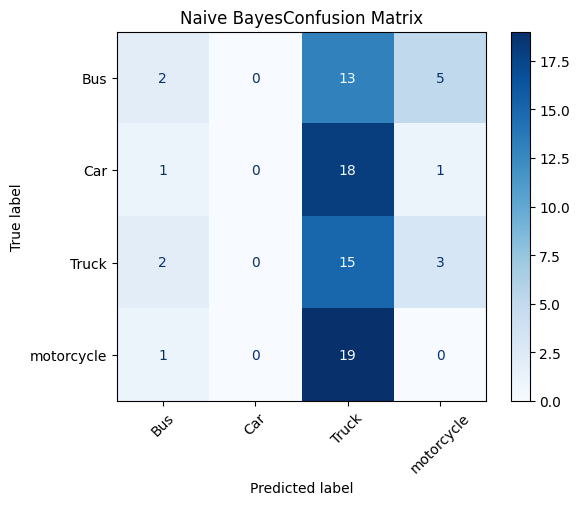

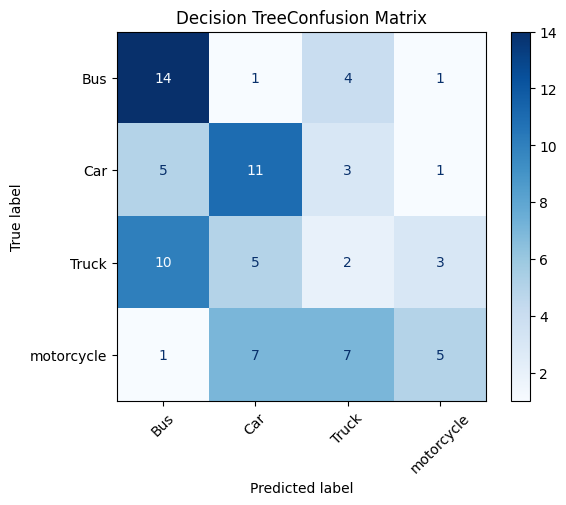

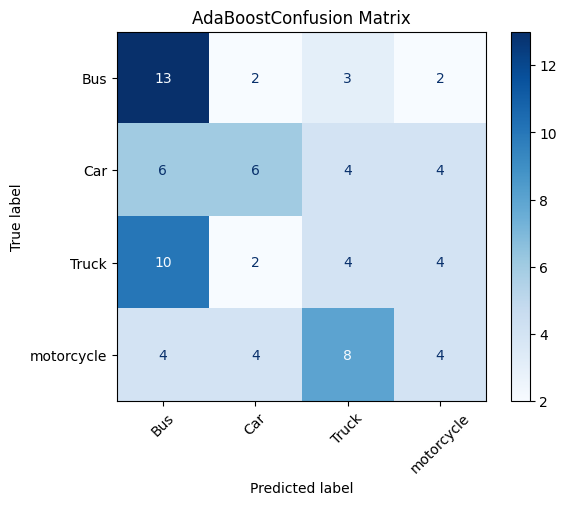

In [49]:
# Import libraries
from sklearn.metrics import ConfusionMatrixDisplay

# Class names
class_names = np.unique(y_train)

# Create confusion matrix for each classifier
for name, model in models.items():

  # Predict test data
  y_pred = model.predict(x_test)

  # Plot Confusion Matrix
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=class_names, display_labels=class_names, cmap="Blues")

  plt.title(name + "Confusion Matrix")
  plt.xticks(rotation=45)
  plt.show()

2(d). Most Frquently Confused Classes

The most frequently confused classes were motorcycle and truck. Across the three classifiers, these two classes were confused 42 times in total. One possible reason is that the 36-dimensional edge histograms capture edge information but do not fully preserve the shapes and spatial arrangements of vehicles. This may make some motorcycles and trucks difficult to distinguish, especially when images contain different viewing angles or backgrounds.

In [50]:
import zipfile
zip_path = "/content/drive/MyDrive/Programming Assignment/archive.zip"
with zipfile.ZipFile(zip_path, "r") as z:
  print(z.namelist()[:20])

['Dataset/Bus/Image_1.jpg', 'Dataset/Bus/Image_10.jpg', 'Dataset/Bus/Image_100.jpg', 'Dataset/Bus/Image_11.jpg', 'Dataset/Bus/Image_12.jpg', 'Dataset/Bus/Image_13.jpg', 'Dataset/Bus/Image_14.jpg', 'Dataset/Bus/Image_15.jpg', 'Dataset/Bus/Image_16.jpg', 'Dataset/Bus/Image_17.jpg', 'Dataset/Bus/Image_18.jpg', 'Dataset/Bus/Image_19.jpg', 'Dataset/Bus/Image_2.jpg', 'Dataset/Bus/Image_20.jpg', 'Dataset/Bus/Image_21.jpg', 'Dataset/Bus/Image_22.jpg', 'Dataset/Bus/Image_23.jpg', 'Dataset/Bus/Image_24.png', 'Dataset/Bus/Image_25.png', 'Dataset/Bus/Image_26.jpg']


2(e). Display Two Misclassified Images

In [51]:
# Find mistakes using one classifier
for name, model in models.items():
  y_pred = model.predict(x_test)

  wrong = np.where(((np.array(y_test) == "motorcycle") & (y_pred == "Truck")) | ((np.array(y_test) == "Truck") & (y_pred == "motorcycle")))[0]

  if len(wrong) >= 2:
    print("Classifier:", name)
    print("Misclassified images:", len(wrong))
    break

Classifier: Naive Bayes
Misclassified images: 22


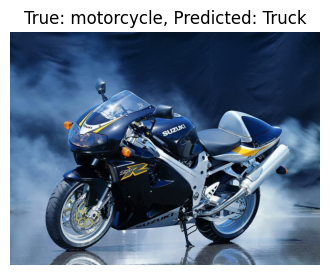

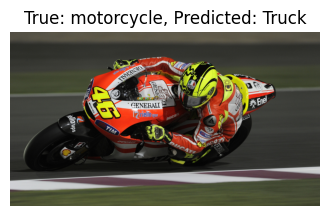

In [52]:
# Display two images
if len(wrong) >= 2:
  for i in wrong[:2]:
    img = original_images[int(test_idx[i])]

    plt.figure(figsize=(4, 4))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"True: {y_test[i]}, Predicted: {y_pred[i]}")
    plt.axis("off")
    plt.show()

else:
  print("Fewer than two matching errors found.")

In [53]:
from sklearn.metrics import confusion_matrix
# Get Naive Bayes Predictions
y_pred = models["Naive Bayes"].predict(x_test)

# Find the most confused pair
labels = np.unique(y_test)
cm = confusion_matrix(y_test, y_pred, labels=labels)

# Ignore correct predictions
np.fill_diagonal(cm, 0)

# Find highest confusion
i, j = np.unravel_index(np.argmax(cm), cm.shape)

print("True class:", labels[i])
print("Predicted class:", labels[j])
print("Number of mistakes:", cm[i,j])

True class: motorcycle
Predicted class: Truck
Number of mistakes: 19


The Naive Bayes classifier incorrectly classified 19 motorcycles images as trucks. This was the most frequently confused pair. The two displayed images are examples of this mistake. This may happen because motorcycles and trucks can have similar edge patterns in their images. The 36-dimensional edge histogram features may not capture enough details to distinguish them correctly.

Section 3: Model Selection and Model Complexity

In [54]:
# Select two classes
class1 = "Car"
class2 = "Truck"

# Select only Car and Truck images
mask = np.isin(y, [class1, class2])

x_two = x[mask]
y_two = y[mask]

print("Selected classes:", np.unique(y_two))
print("Total images:", len(y_two))


Selected classes: ['Car' 'Truck']
Total images: 200


In [55]:
# Split Car and Truck data
from sklearn.model_selection import train_test_split

x_train_2, x_test_2, y_train_2, y_test_2 = train_test_split(x_two, y_two, test_size=0.2, random_state=42, stratify=y_two)

print("Training images:", len(y_train_2))
print("Testing images:", len(y_test_2))


Training images: 160
Testing images: 40


3(a).Prepare cross-validation

In [56]:
# Import required libraries
from sklearn.svm import LinearSVC
from  sklearn.model_selection import KFold, StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline

# C values required by professor
C_values = [0.01, 0.1, 1, 10, 100, 1000]

# Standard 5-fold
standard_cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Stratified 5-fold
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [57]:
# Calculate training and validation errors
from sklearn.preprocessing import StandardScaler

results = []

for c in C_values:
  model = make_pipeline(StandardScaler(), LinearSVC(C=c))

  for name, cv in[("Standard", standard_cv), ("Stratified", stratified_cv)]:
    scores = cross_validate(model, x_train_2, y_train_2, cv=cv, scoring="accuracy", return_train_score=True)

    train_error = (1- scores["train_score"].mean())*100
    val_error = (1- scores["test_score"].mean())*100

    results.append([c, name, train_error, val_error])

In [58]:
# Display error results
df = pd.DataFrame(results, columns=["C", "CV Method", "Training Error", "Validation Error"])

print(df.round(2))

          C   CV Method  Training Error  Validation Error
0      0.01    Standard           39.22             54.37
1      0.01  Stratified           34.22             42.50
2      0.10    Standard           33.28             45.63
3      0.10  Stratified           30.00             42.50
4      1.00    Standard           30.31             42.50
5      1.00  Stratified           28.28             37.50
6     10.00    Standard           22.81             37.50
7     10.00  Stratified           23.28             35.00
8    100.00    Standard           17.03             32.50
9    100.00  Stratified           17.34             35.00
10  1000.00    Standard           13.44             33.13
11  1000.00  Stratified           12.81             32.50


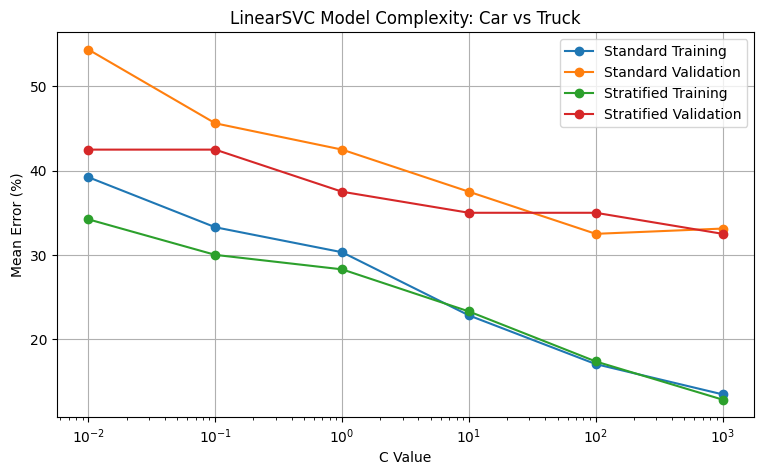

In [59]:
# PLot four error curves
standard = df[df["CV Method"] == "Standard"]
stratified = df[df["CV Method"] == "Stratified"]

plt.figure(figsize=(9,5))

plt.plot(standard["C"], standard["Training Error"], marker="o", label="Standard Training")

plt.plot(standard["C"], standard["Validation Error"], marker="o", label="Standard Validation")

plt.plot(stratified["C"], stratified["Training Error"], marker="o", label="Stratified Training")

plt.plot(stratified["C"], stratified["Validation Error"], marker="o", label="Stratified Validation")

plt.xscale("log")
plt.xlabel("C Value")
plt.ylabel("Mean Error (%)")
plt.title("LinearSVC Model Complexity: Car vs Truck")
plt.legend()
plt.grid(True)
plt.show()

3(b). Find the best C values and Check class distribution in folds

In [60]:
# Find best C values
best_standard = standard.loc[standard["Validation Error"].idxmin()]

best_stratified = stratified.loc[stratified["Validation Error"].idxmin()]

print("Best Standard C:", best_standard["C"])
print("Standard Error:", best_standard["Validation Error"])

print("Best Stratified C:", best_stratified["C"])
print("Startified Error:", best_stratified["Validation Error"])


Best Standard C: 100.0
Standard Error: 32.49999999999999
Best Stratified C: 1000.0
Startified Error: 32.49999999999999


In [61]:
# Check class distribution in each fold
for name, cv in [("Standard", standard_cv), ("Stratified", stratified_cv)]:
  print("\n", name)

  for i, (_, val_idx) in enumerate(cv.split(x_train_2, y_train_2), 1):
    print("Fold", i, pd.Series(y_train_2[val_idx]).value_counts().to_dict())


 Standard
Fold 1 {'Truck': 18, 'Car': 14}
Fold 2 {'Car': 16, 'Truck': 16}
Fold 3 {'Truck': 17, 'Car': 15}
Fold 4 {'Truck': 20, 'Car': 12}
Fold 5 {'Car': 23, 'Truck': 9}

 Stratified
Fold 1 {'Car': 16, 'Truck': 16}
Fold 2 {'Car': 16, 'Truck': 16}
Fold 3 {'Truck': 16, 'Car': 16}
Fold 4 {'Truck': 16, 'Car': 16}
Fold 5 {'Car': 16, 'Truck': 16}




*   Which C gives the lowest mean validation error for each cross-validation approach?

Standard 5-fold cross-validation gives the lowest validation error of 32.50% at C=100. Stratified 5-fold cross-validation gives the lowest validation error of 32.50% at C=1000.
*   How does increasing C affect the model complpexity of the SVM?

Increasing C reduces regularization, allowing the SVM to fit the training data more closely. This increases the model's effective complexity and may increase overfitting.



*   Is there evidence of underfitting? Explain using the training and validation error?

Yes. At smaller C values, both training and validation errors are relatively high. This suggests that the model is too strongly regularized and may be underfitting.
*   Is there evidence of overfitting? Explain using the training and validation errors.

A larger C allows the SVM to fit the training data more clearly. This may cause overfitting if training error becomes very low while validation error remains high or increases. In my results, there is no clear evidence of overfitting at larger C values because validation error does not increase significantly.



*   Are the results from standard and stratified cross-validation similar? If they are different, inspect the class distributions in the folds and give a possible explanation.

The results show similar minimum validation errors but different error patterns. Standard cross-validation can have unequal proportions of Cars and Truck images in each fold. Stratified cross-validation keeps the class proportions more balanced. This may explain why their validation errors are different.









3(c). Test the best SVM model

In [62]:
from sklearn.metrics import accuracy_score

# Best C from stratified cross-validation
best_c = 1000

# Create model
model = make_pipeline(StandardScaler(), LinearSVC(C=best_c))

# Train model
model.fit(x_train_2, y_train_2)

# Predict test data
y_pred = model.predict(x_test_2)

# Calculate test error
test_error = (1- accuracy_score(y_test_2, y_pred))* 100

print("Best C:", best_c)
print("Test Error:", round(test_error, 2), "%")
print("Cross-validation Error: 32.50%")

Best C: 1000
Test Error: 35.0 %
Cross-validation Error: 32.50%


I selected C=1000 because it gave the lowest validation error of 32.50%  using stratified 5-fold cross-validation. I trained the LinearSVC model using this C value and tested it on unseen images. The test error was 35% and giving test accuracy of 65%. The difference between validation and test error was only  2.5% points, so the results are reasonably consistent. However, the model still made some classification mistakes.

Section 4: Final Analysis

Which classifier should I use for this image dataset?

I compared three classifiers: Naive Bayes, Decision Tree, and AdaBoost using 36-dimensional edge histograms. Among these three classifiers, Decision Tree achieved the highest mean cross-validation accuracy of 43.75% and test accuracy of 40%. However, its performance varied more across the folds.

The confusion matrix showed that motorcycles and trucks were frequently confused. The 36-dimensional edge histograms are useful for capturing image shapes, but they do not capture all visual details, such as color and texture.

I also tested LinearSVC in two classes, Car and Truck. It achieved 65% test accuracy, but this result cannot be directly compared with the four-class classifiers.

Based on my results, I would recommend Decision Tree among the three assigned classifiers because it achieved the highest test accuracy. However, cross-validation accuracy and variability should also be considered before making a final decision.

To improve performance, I would try using more detailed image features or better image preprocessing.

I learned that different classifiers could produce different results on the same dataset. Cross-validation helps compare models, while test accuracy shows how well they perform on unseen data.

